# NEURAL NETWORKS AND DEEP LEARNING PROJECT

---
Project: Human Activity Recognition with Wi-Fi (SHARP dataset)

Reference papers:
1. F. Meneghello et al., "SHARP: Environment and Person Independent Activity Recognition With Commodity IEEE 802.11 Access Points," IEEE TMC, 2023.
2. F. Meneghello et al., "A CSI Dataset for Wireless Human Sensing on 80 MHz Wi-Fi Channels," IEEE Comm. Mag., 2023.
3. P. Khosla at al., "Supervised Contrastive Learning", Advances in Neural Information Processing Systems (NeurIPS), Dec., 2020

## 1. Setup

In [ ]:
!pip -q install gdown

import os
import zipfile
import gdown

FILE_URL = "https://drive.google.com/file/d/1qOlNReZNQsv8Agmn6bD47E0w7fqlaOgA/view?usp=sharing"

ZIP_PATH = "/content/doppler_traces.zip"

EXTRACT_DIR = "/content/dataset"    # Extract on the local Colab disk


In [ ]:
# Download only if it hasn't been done yet in this runtime
# fuzzy=True lets gdown extract the file id from a normal "view" link, no need to hand-edit the URL
if not os.path.exists(ZIP_PATH):
    gdown.download(url=FILE_URL, output=ZIP_PATH, quiet=False, fuzzy=True)

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)  # Unpacks the whole archive into EXTRACT_DIR

print(os.listdir(EXTRACT_DIR))  # Sanity check: this should show the S1a, S1b, ... folders (or a "doppler_traces" folder containing them)


Downloading...
From (original): https://drive.google.com/uc?id=1qOlNReZNQsv8Agmn6bD47E0w7fqlaOgA
From (redirected): https://drive.google.com/uc?id=1qOlNReZNQsv8Agmn6bD47E0w7fqlaOgA&confirm=t&uuid=7c650606-fd93-4bfc-85a6-535be46138d8
To: /content/doppler_traces.zip
100%|██████████| 799M/799M [00:07<00:00, 111MB/s]


['doppler_traces']


In [ ]:
# DATASET_ROOT must point to the folder that directly contains the S1a, S1b, S2a, ... subfolders.
DATASET_ROOT = os.path.join(EXTRACT_DIR, "doppler_traces")
if not os.path.isdir(DATASET_ROOT):
    DATASET_ROOT = EXTRACT_DIR  # fallback: the S1a, S1b, ... folders are directly at the root

# Remove the .placeholder from the dataset
placeholder_path = os.path.join(DATASET_ROOT, ".placeholder")
if os.path.exists(placeholder_path):
    os.remove(placeholder_path)

print("DATASET_ROOT:", DATASET_ROOT)
print(sorted(os.listdir(DATASET_ROOT))[:5], "...")


DATASET_ROOT: /content/dataset/doppler_traces
['S1a', 'S1b', 'S1c', 'S2a', 'S2b'] ...


In [ ]:
import gc
import re
import pickle

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from tqdm import tqdm

seed = 0
torch.manual_seed(seed)   # fixes PyTorch's random initialization/shuffling for reproducibility
np.random.seed(seed)

device = "cuda" if torch.cuda.is_available() else "cpu"  # use the Colab GPU if you enabled one
print("Device:", device)


Device: cuda


## 2. Understanding and loading the dataset

Each file in `doppler_traces/<env>/` is a **Doppler spectrogram trace**: a pickled numpy array of shape `(T, 100)`, where `T` is the number of time samples (it varies a lot from file to file) and `100` is the number of Doppler velocity bins.

The file name encodes three things, e.g. `S4a_J2_stream_1.txt`:
- `S4a`: the environment/measurement set (one of 12 folders: `S1a, S1b, S1c, S2a, S2b, S3a, S4a, S4b, S5a, S6a, S6b, S7a`),
- `J2`: the activity letter (`J`), possibly followed by a repetition number (`2`),
- `stream_1`: which of the 4 receiving antennas the trace comes from.

The activity letters used across the dataset are: `E` (empty room), `J` (jumping), `L` (sitting still), `R` (running), `W` (walking), plus a few extra ones (`C`, `S`, `H`, `LOS`) that only appear in some environments. To keep things simple and comparable across **all** environments, we only use the 5 core activities that are present everywhere: **E, J, L, R, W**. This matches the 5-class setup used in the original SHARP paper.

The baseline architecture expects, as input, a single-channel image of shape `1 x 340 x 100`: 340 consecutive time samples (about 2 seconds) x 100 Doppler bins. Since each file is much longer than 340 samples, we cut every trace into windows of length 340. Each window becomes one training example, labeled with the activity of the file it came from.

Initial version has a window by exactly `WIN_LEN` samples per step, so consecutive windows never shared a sample and a trace of length `T` yielded only `T // 340` windows. The actual code advances it by `STRIDE = 30` samples instead, so consecutive windows overlap by 310 of their 340 samples and the same traces yield ~10x more windows. `STRIDE = 30` is not an arbitrary choice: it is the stride the authors' own code uses when it builds the training set.

Two honest caveats. Overlapping windows are strongly correlated, so the effective number of independent examples grows much less than 10x; and because the train/val split below is random at window level, a window and its overlapping neighbours can land on opposite sides of that split, which makes the validation loss optimistic and therefore affects when early stopping fires. It does not affect the reported test accuracy: the test set is a completely different set of environments, so there is no train/test leakage.

Regarding multi-antenna decision fusion: for a given recording, the 4 antenna streams all have exactly the same number of time samples `T`. They are 4 simultaneous recordings of the very same event. This means that "window number `k`" of a stream and "window number `k`" of another stream correspond to the same real time window, just observed by 4 different antennas. We keep track of this with a `group_id` per window (see `build_dataset` below), so that later we can combine the 4 antennas' predictions for the same real time window.


In [ ]:
ACTIVITIES = ["E", "J", "L", "R", "W"]  # The 5 core activities, common to every environment
WIN_LEN = 340   # Number of time samples per window (as in the baseline architecture, ~2 seconds)
STRIDE = 30     # The window advances by 30 samples instead of WIN_LEN -> sliding windows
N_DOPPLER_BINS = 100

# matches e.g. "S4a_J2_stream_1.txt" -> groups: ("S4a", "J2", "1")
FNAME_RE = re.compile(r"([A-Za-z0-9]+)_([A-Za-z]+\d*)_stream_(\d)\.txt")


def parse_filename(fname):
    """Extract (environment, activity_letter, antenna_stream, recording_token) from a file name.
    `recording_token` is the activity letter *with* its optional repetition number (e.g. "J2"),
    which uniquely identifies one specific recording within an environment, shared by its 4 antenna streams.
    Returns None if the file does not match the expected naming pattern.
    """
    m = FNAME_RE.match(fname)
    if m is None:
        return None
    env, token, stream = m.group(1), m.group(2), int(m.group(3))
    label = re.match(r"[A-Za-z]+", token).group()  # strip the optional trailing repetition number, e.g. "J2" -> "J"
    return env, label, stream, token


# Which environment folders are used for training/validation, and which are held out for testing.
TRAIN_ENVS = ["S1a", "S1b", "S1c"]

ALL_ENVS = sorted(os.listdir(DATASET_ROOT))
TEST_ENVS = [e for e in ALL_ENVS if e not in TRAIN_ENVS]
print("Train/val environments:", TRAIN_ENVS)
print("Test environments:", TEST_ENVS)


Train/val environments: ['S1a', 'S1b', 'S1c']
Test environments: ['S2a', 'S2b', 'S3a', 'S4a', 'S4b', 'S5a', 'S6a', 'S6b', 'S7a']


In [ ]:
def build_dataset(root_dir, envs_wanted=None, activities=ACTIVITIES, win_len=WIN_LEN, stride=STRIDE):
    """Walk through the environment folders in `envs_wanted`, load every Doppler trace belonging to
    one of `activities`, and cut it into SLIDING windows of length `win_len` that advance by `stride`
    samples.

    Args:
        envs_wanted: list of environment folder names to load, or None for all of them.

    Returns:
        X: float32 array of shape (N, 1, win_len, N_DOPPLER_BINS)
        y: int64 array of shape (N,) with values in [0, len(activities))
        envs: array of shape (N,) with the environment name each window comes from (e.g. "S1a")
        groups: array of shape (N,) with a group id per window, e.g. "S4a_J2_0". Windows with the
                same group id come from the same real time window, recorded simultaneously by the
                4 antennas; used later for multi-antenna decision fusion (section 8).
    """
    # Pass 1: read the traces we need, and count how many windows each of them produces in order to fill a single pre-allocated array
    records = []
    for env in sorted(os.listdir(root_dir)):          # e.g. "S1a", "S1b", ...
        if envs_wanted is not None and env not in envs_wanted:
            continue
        env_dir = os.path.join(root_dir, env)
        if not os.path.isdir(env_dir):
            continue
        for fname in sorted(os.listdir(env_dir)):      # every file inside that environment folder
            parsed = parse_filename(fname)
            if parsed is None:
                continue
            # parsed = parse_filename(fname) is the (env, label, stream, token) tuple returned above;
            _, label, _, token = parsed
            if label not in activities:                # skip the extra activities (C, S, H, LOS, ...)
                continue

            with open(os.path.join(env_dir, fname), "rb") as f:
                trace = np.asarray(pickle.load(f), dtype=np.float32)  # shape (T, 100), T varies per file

            last_start = trace.shape[0] - win_len      # last index at which a full window still fits
            if last_start < 0:                         # trace shorter than one window: nothing to do
                continue
            n_windows = last_start // stride + 1       # windows starting at 0, stride, 2*stride, ...
            records.append([trace, activities.index(label), env, token, n_windows])

    # Pass 2: fill one pre-allocated array, freeing each trace as soon as it has been windowed
    n_total = sum(r[4] for r in records)
    X = np.empty((n_total, 1, win_len, N_DOPPLER_BINS), dtype=np.float32)
    y = np.empty(n_total, dtype=np.int64)
    env_list, group_list = [], []

    pos = 0
    for rec in records:
        trace, label_idx, env, token, n_windows = rec
        X[pos: pos + n_windows, 0] = np.stack([trace[k * stride: k * stride + win_len]
                                               for k in range(n_windows)])
        y[pos: pos + n_windows] = label_idx
        env_list.extend([env] * n_windows)                     # same environment for every window of this file
        group_list.extend([f"{env}_{token}_{k}" for k in range(n_windows)])
        pos += n_windows
        rec[0] = None                                          # drop the reference: free the trace right away

    del records
    gc.collect()
    return X, y, np.array(env_list), np.array(group_list)


# The train/val and the test windows are built separately
X_trainval, y_trainval, envs_trainval, groups_trainval = build_dataset(DATASET_ROOT, TRAIN_ENVS)
X_test, y_test, envs_test, groups_test = build_dataset(DATASET_ROOT, TEST_ENVS)

print(f"Sliding window: WIN_LEN={WIN_LEN}, STRIDE={STRIDE} "
      f"({100 * (1 - STRIDE / WIN_LEN):.0f}% overlap between consecutive windows)")
print("  train/val X_trainval shape:", X_trainval.shape, f"({X_trainval.nbytes / 1e9:.2f} GB)")
print("  test      X_test     shape:", X_test.shape,     f"({X_test.nbytes / 1e9:.2f} GB)")
print(f"  windows in total: {len(y_trainval) + len(y_test)}")
for i, act in enumerate(ACTIVITIES):
    print(f"  {act}: {(y_trainval == i).sum()} train/val + {(y_test == i).sum()} test windows")


Sliding window: WIN_LEN=340, STRIDE=30 (91% overlap between consecutive windows)
  train/val X_trainval shape: (36592, 1, 340, 100) (4.98 GB)
  test      X_test     shape: (115728, 1, 340, 100) (15.74 GB)
  windows in total: 152320
  E: 7324 train/val + 26616 test windows
  J: 6656 train/val + 17460 test windows
  L: 7564 train/val + 26700 test windows
  R: 7564 train/val + 22588 test windows
  W: 7484 train/val + 22364 test windows


### Quick sanity check: plot one window per activity

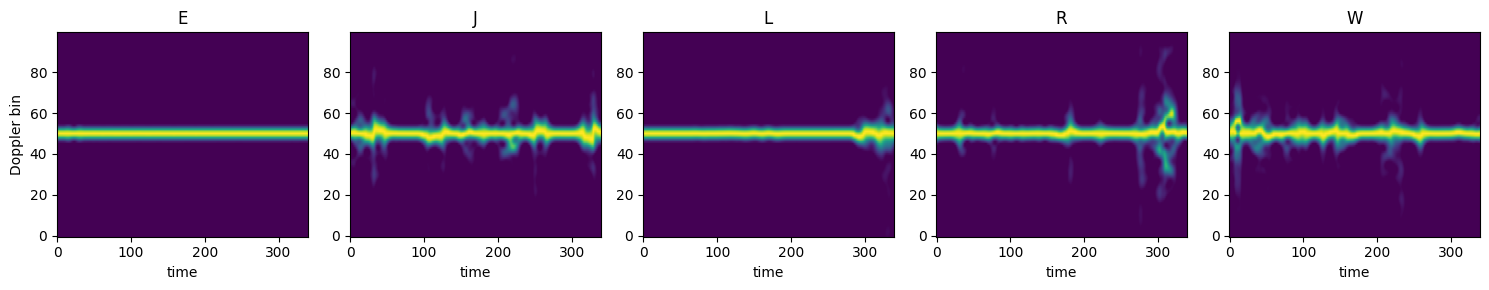

In [ ]:
fig, axs = plt.subplots(1, len(ACTIVITIES), figsize=(15, 3))
for i, act in enumerate(ACTIVITIES):
    idx = np.where(y_trainval == i)[0][0]     # index of the first train/val window belonging to this activity
    axs[i].imshow(X_trainval[idx, 0].T, aspect="auto", origin="lower", cmap="viridis")  # .T: rows=Doppler bins, cols=time, for a readable plot
    axs[i].set_title(act)
    axs[i].set_xlabel("time")
axs[0].set_ylabel("Doppler bin")
plt.tight_layout()
plt.show()


## 3. Dataset class and train/val/test split

Everything is precomputed once and wrapped in a minimal `Dataset`. With `STRIDE = 30` the materialised windows take ~20 GB of RAM, with a peak of ~31 GB. If the runtime runs out of memory, raise `STRIDE` in section 2.


In [ ]:
class DopplerDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)  # keep everything already converted to tensors, no per-item work needed
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


In [ ]:
# The environment-based split has already happened in section 2
# envs_test  = environment name of each test window (used to evaluate subsets of the test set separately)
# groups_test = group id of each test window (used for multi-antenna decision fusion)

# only the train/val windows are split randomly (they all come from the same environments anyway)
# stratify=... keeps the same class proportions in both splits
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15, stratify=y_trainval, random_state=seed
)

# train_test_split *copies*, so X_trainval is now a redundant duplicate of X_train + X_val
del X_trainval, y_trainval
gc.collect()

train_dataset = DopplerDataset(X_train, y_train)
val_dataset = DopplerDataset(X_val, y_val)
test_dataset = DopplerDataset(X_test, y_test)

print("Train/Val/Test sizes:", len(train_dataset), len(val_dataset), len(test_dataset))

BATCH_SIZE = 64
train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)   # shuffle=True: reshuffle batches every epoch, only needed for training
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
# shuffle=False keeps test_dataloader's sample order identical to
# X_test/y_test/groups_test, which section 8 relies on to match predictions back to their group id
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


Train/Val/Test sizes: 31103 5489 115728


## 4. Baseline model

We implement the "Baseline model" from the project slides. It is composed by 3 parallel branches that all take the `1 x 340 x 100` input and produce feature maps of the same spatial size, so that they can be concatenated along the channel dimension:

- Branch 1: `MaxPool(2x2, stride 2)` -> 1 channel
- Branch 2: `Conv(5 filters, 2x2, stride 2) + ReLU` -> 5 channels
- Branch 3: `Conv(3 filters, 1x1, stride 1) -> Conv(6 filters, 2x2, stride 1, pad 2) -> Conv(9 filters, 4x4, stride 2) + ReLU` -> 9 channels

The 3 branches are concatenated, reduced back to 3 channels with a `1x1` convolution, flattened, passed through `Dropout(0.2)` and a final `Dense` layer with one output per activity class.


In [ ]:
class BaselineHARNet(nn.Module):
    def __init__(self, num_classes=len(ACTIVITIES)):
        super().__init__()

        # branch 1: just downsamples, no learnable parameters, keeps 1 channel
        self.branch1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # branch 2: a single strided conv, halves both spatial dims
        self.branch2 = nn.Sequential(
            nn.Conv2d(1, 5, kernel_size=2, stride=2),
            nn.ReLU(),
        )

        # branch 3: deeper/finer-grained path. padding=2 on the middle conv is what makes its
        # output spatial size match branch 1 and 2 after the final stride-2 conv
        self.branch3 = nn.Sequential(
            nn.Conv2d(1, 3, kernel_size=1, stride=1),
            nn.ReLU(),
            nn.Conv2d(3, 6, kernel_size=2, stride=1, padding=2),
            nn.ReLU(),
            nn.Conv2d(6, 9, kernel_size=4, stride=2),
            nn.ReLU(),
        )

        # after concatenation the 3 branches give 1 + 5 + 9 = 15 channels; this 1x1 conv mixes/reduces them to 3
        self.reduce = nn.Sequential(
            nn.Conv2d(1 + 5 + 9, 3, kernel_size=1, stride=1),
            nn.ReLU(),
        )

        self.dropout = nn.Dropout(0.2)  # regularization: randomly zeroes 20% of the flattened features during training
        self.classifier = nn.Linear(3 * 170 * 50, num_classes)  # one output score (logit) per activity class

    def forward(self, x):
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        out = torch.cat([b1, b2, b3], dim=1)   # concatenate along the channel dimension (dim=1): requires equal H, W across branches
        out = self.reduce(out)
        out = torch.flatten(out, start_dim=1)  # (batch, channels, H, W) -> (batch, channels*H*W), keeping the batch dim
        out = self.dropout(out)
        out = self.classifier(out)             # returns raw logits, softmax is applied inside CrossEntropyLoss
        return out


model = BaselineHARNet().to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Trainable parameters: {count_parameters(model):,}")
# Expected ~128,535, matching the SHARP paper's baseline model.


Trainable parameters: 128,535


Sanity check: verify the model runs on a dummy batch and the output shape is `(batch_size, num_classes)`.

In [ ]:
with torch.no_grad():                                       # no need to track gradients just to check the output shape
    dummy = torch.zeros(4, 1, WIN_LEN, N_DOPPLER_BINS).to(device)  # a fake batch of 4 samples
    out = model(dummy)
    print("Output shape:", out.shape)  # should be (4, 5): 4 samples, 5 class scores each


Output shape: torch.Size([4, 5])


## 5. Training

Standard supervised classification training loop, using: cross-entropy loss, Adam optimizer, one pass over train + validation per epoch.

**Early stopping.** Instead of always training for a fixed number of epochs, we stop as soon as the validation loss hasn't improved for `PATIENCE` consecutive epochs. This protects against overfitting (train loss keeps dropping while val loss plateaus or climbs back up) without having to guess the "right" number of epochs in advance. Since early stopping decides the real stopping point, the epoch budget (`EPOCHS = 100`) is only a safety ceiling that should rarely be reached. We keep the model weights from the best epoch (lowest validation loss), not simply the weights from the last epoch, and restore them before evaluating on the test set.

The training set still pools windows from all 4 antenna streams together. Multi-antenna information is only used later, at evaluation time (section 8), through decision fusion.


In [ ]:
criterion = nn.CrossEntropyLoss()  # combines log-softmax + negative log-likelihood, expects raw logits + integer class labels
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 100      # upper bound on the number of epochs; early stopping will typically stop training well before this
PATIENCE = 12


In [ ]:
def run_epoch(dataloader, model, criterion, optimizer=None):
    is_train = optimizer is not None      # if no optimizer is passed, we're just evaluating (val/test)
    model.train() if is_train else model.eval()  # toggles dropout on/off

    total_loss, all_preds, all_labels = 0.0, [], []
    with torch.set_grad_enabled(is_train):        # disables autograd during evaluation, saves memory/time
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            if is_train:
                optimizer.zero_grad()   # reset gradients accumulated from the previous batch
                loss.backward()         # backpropagation: compute gradients of the loss w.r.t. all parameters
                optimizer.step()        # update the parameters using those gradients

            total_loss += loss.item() * batch_x.size(0)            # un-average the batch loss so we can average over the whole dataset later
            all_preds.append(logits.argmax(dim=1).detach().cpu())  # predicted class = highest-scoring logit
            all_labels.append(batch_y.detach().cpu())

    avg_loss = total_loss / len(dataloader.dataset)
    acc = accuracy_score(torch.cat(all_labels), torch.cat(all_preds))
    return avg_loss, acc


In [ ]:
train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_loss = float("inf")
epochs_without_improvement = 0
best_state = None   # will hold a copy of the model weights at the best (lowest validation loss) epoch

for epoch in tqdm(range(EPOCHS)):
    tr_loss, tr_acc = run_epoch(train_dataloader, model, criterion, optimizer)     # optimizer passed -> training mode
    va_loss, va_acc = run_epoch(val_dataloader, model, criterion, optimizer=None)  # no optimizer -> evaluation only

    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    train_accs.append(tr_acc)
    val_accs.append(va_acc)

    print(f"Epoch {epoch+1}/{EPOCHS} - train_loss: {tr_loss:.4f}, train_acc: {tr_acc:.4f} "
          f"- val_loss: {va_loss:.4f}, val_acc: {va_acc:.4f}")

    if va_loss < best_val_loss:                     # new best model found
        best_val_loss = va_loss
        epochs_without_improvement = 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}  # snapshot the weights
    else:
        epochs_without_improvement += 1             # no improvement this epoch (covers both "plateaued" and "got worse")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping triggered: no improvement in validation loss for {PATIENCE} epochs "
              f"(stopped after epoch {epoch+1}).")
        break

if best_state is not None:
    model.load_state_dict(best_state)  # restore the best-epoch weights before evaluating on the test set
    print(f"Restored model weights from the best epoch (val_loss={best_val_loss:.4f}).")


  1%|          | 1/100 [00:11<18:09, 11.01s/it]

Epoch 1/100 - train_loss: 1.1134, train_acc: 0.4574 - val_loss: 0.9814, val_acc: 0.5380


  2%|▏         | 2/100 [00:21<17:30, 10.72s/it]

Epoch 2/100 - train_loss: 0.9723, train_acc: 0.5437 - val_loss: 0.9718, val_acc: 0.5449


  3%|▎         | 3/100 [00:32<17:09, 10.62s/it]

...

Epoch 25/100 - train_loss: 0.5749, train_acc: 0.7456 - val_loss: 0.8509, val_acc: 0.6515


 26%|██▌       | 26/100 [04:35<12:58, 10.52s/it]

Epoch 26/100 - train_loss: 0.5665, train_acc: 0.7492 - val_loss: 0.8536, val_acc: 0.6502


 26%|██▌       | 26/100 [04:46<13:34, 11.01s/it]

Epoch 27/100 - train_loss: 0.5626, train_acc: 0.7501 - val_loss: 0.8653, val_acc: 0.6409
Early stopping triggered: no improvement in validation loss for 12 epochs (stopped after epoch 27).
Restored model weights from the best epoch (val_loss=0.8051).


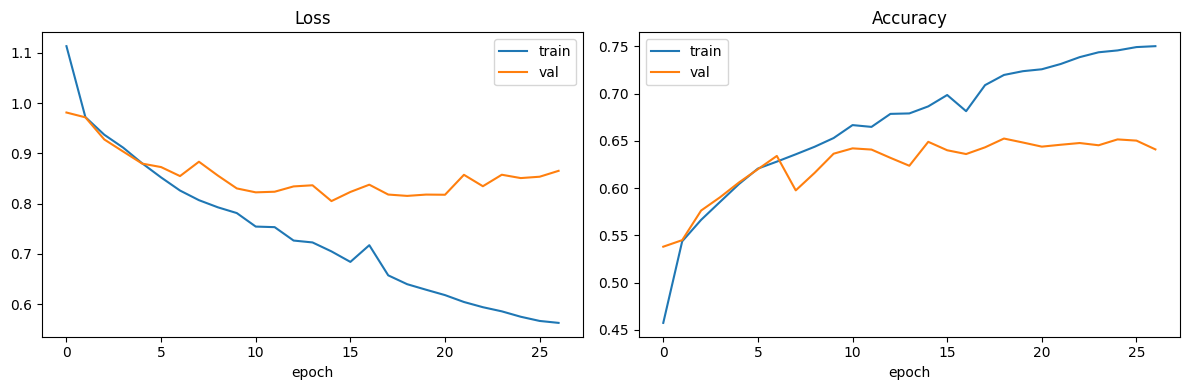

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(train_losses, label="train")
axs[0].plot(val_losses, label="val")
axs[0].set_title("Loss")
axs[0].set_xlabel("epoch")
axs[0].legend()

axs[1].plot(train_accs, label="train")
axs[1].plot(val_accs, label="val")
axs[1].set_title("Accuracy")
axs[1].set_xlabel("epoch")
axs[1].legend()
plt.tight_layout()
plt.show()


## 6. Test set evaluation (all test environments together)

`TRAIN_ENVS` currently contains a single measurement set (just `S1`), while `TEST_ENVS` is every other set in the dataset.

The confusion matrices below are row-normalized (`normalize="true"`): each row (a true activity) sums to 1, so every cell is a fraction in `[0, 1]`.


In [ ]:
test_loss, test_acc = run_epoch(test_dataloader, model, criterion, optimizer=None)  # optimizer=None because no weight updates on test data
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")


Test loss: 0.9595, Test accuracy: 0.6008


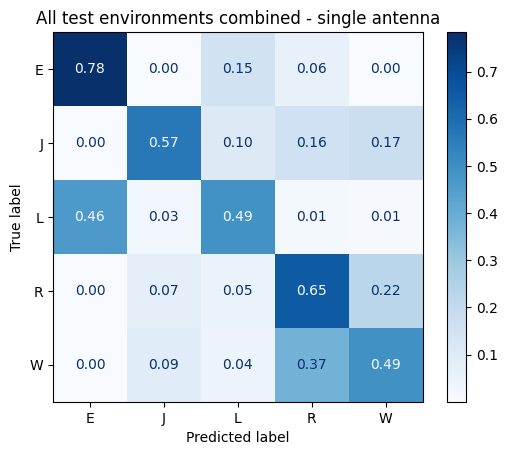

In [ ]:
model.eval()
all_preds, all_labels = [], []
with torch.no_grad():
    for batch_x, batch_y in test_dataloader:
        batch_x = batch_x.to(device)
        logits = model(batch_x)
        all_preds.append(logits.argmax(dim=1).cpu())  # take the most likely class per sample
        all_labels.append(batch_y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

# normalize="true": each row (true class) sums to 1, so every cell is in [0, 1] instead of a raw count
cm = confusion_matrix(all_labels, all_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
disp.plot(cmap="Blues", values_format=".2f")   # show 2 decimals (e.g. 0.85) instead of raw counts
plt.title("All test environments combined - single antenna")
plt.show()


## 7. Test set evaluation (grouped by measurement set)

Evaluate every test set group in the data set independently.


In [ ]:
def env_group(env_name):
    """Map an environment folder name to its measurement-set group, e.g. "S4a" -> "S4", "S4b" -> "S4"."""
    m = re.match(r"(S\d+)", env_name)
    return m.group(1) if m else env_name


# group the test environments by measurement set (e.g. "S4": ["S4a", "S4b"])
test_groups = {}
for env_name in TEST_ENVS:
    group = env_group(env_name)
    test_groups.setdefault(group, []).append(env_name)

print(test_groups)


{'S2': ['S2a', 'S2b'], 'S3': ['S3a'], 'S4': ['S4a', 'S4b'], 'S5': ['S5a'], 'S6': ['S6a', 'S6b'], 'S7': ['S7a']}


S2 (S2a, S2b): n=31696, loss=0.9663, acc=0.6163


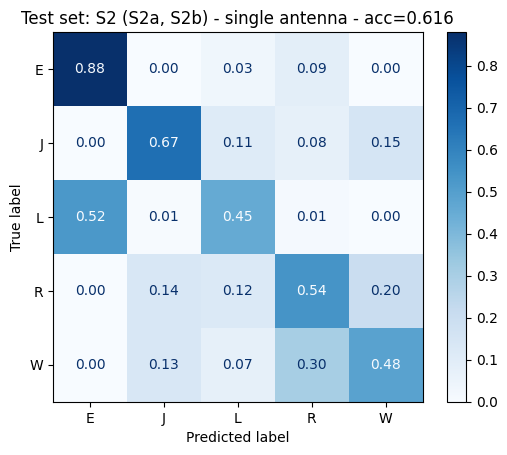

S3 (S3a): n=12380, loss=0.8695, acc=0.6326


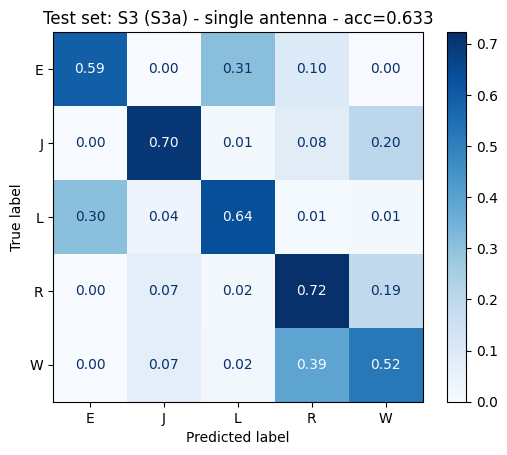

S4 (S4a, S4b): n=24444, loss=0.9713, acc=0.5707


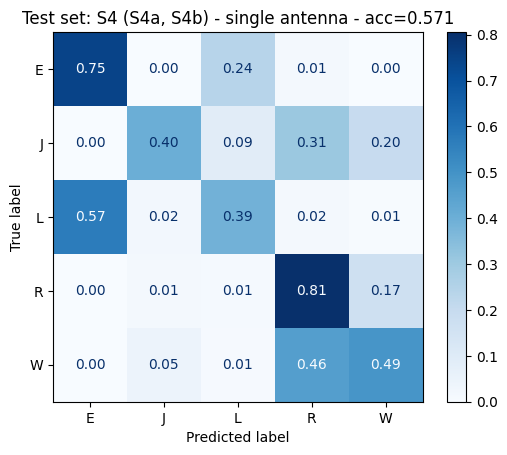

S5 (S5a): n=12248, loss=0.9585, acc=0.5799


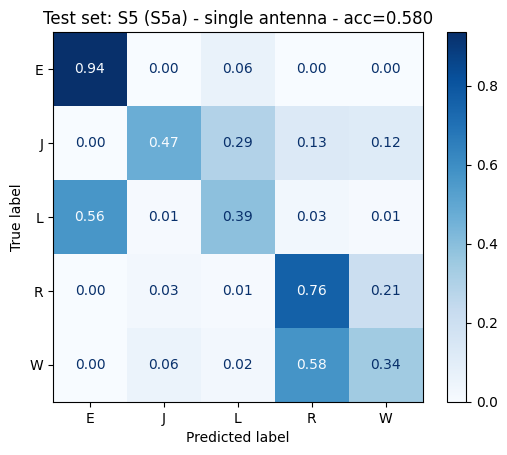

S6 (S6a, S6b): n=23472, loss=0.9776, acc=0.5827


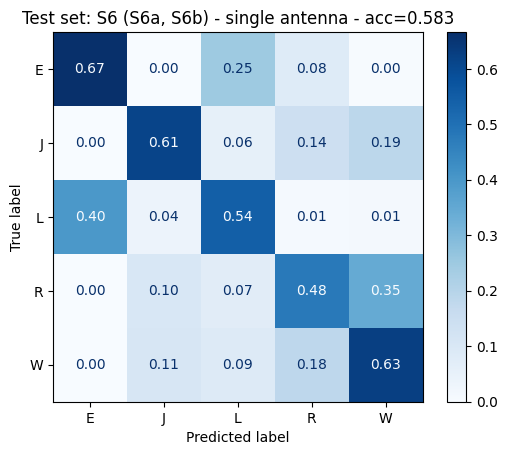

S7 (S7a): n=11488, loss=0.9767, acc=0.6471


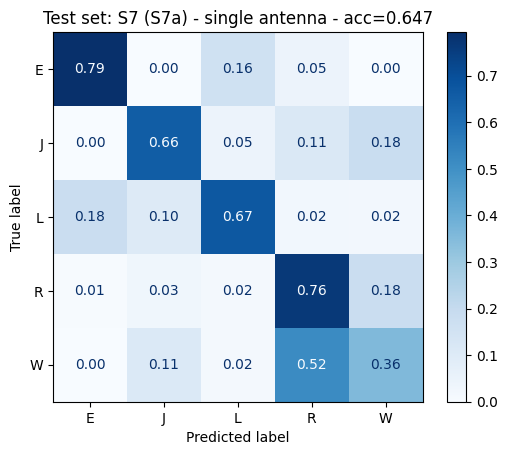

In [ ]:
def evaluate_environment_group(group_name, member_envs):
    mask = np.isin(envs_test, member_envs)   # windows belonging to any environment in this group
    X_grp, y_grp = X_test[mask], y_test[mask]
    if len(y_grp) == 0:
        print(f"{group_name}: no windows found, skipping")
        return None

    grp_dataset = DopplerDataset(X_grp, y_grp)
    grp_dataloader = DataLoader(grp_dataset, batch_size=BATCH_SIZE, shuffle=False)

    loss, acc = run_epoch(grp_dataloader, model, criterion, optimizer=None)
    print(f"{group_name} ({', '.join(member_envs)}): n={len(y_grp)}, loss={loss:.4f}, acc={acc:.4f}")

    model.eval()
    preds, labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in grp_dataloader:
            batch_x = batch_x.to(device)
            logits = model(batch_x)
            preds.append(logits.argmax(dim=1).cpu())
            labels.append(batch_y)
    preds = torch.cat(preds).numpy()
    labels = torch.cat(labels).numpy()

    # labels=range(len(ACTIVITIES)) keeps the matrix 5x5 even if this group has 0 samples of some class;
    # normalize="true" keeps every cell in [0, 1] regardless of how many windows this group has
    cm = confusion_matrix(labels, preds, labels=list(range(len(ACTIVITIES))), normalize="true")
    disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
    disp.plot(cmap="Blues", values_format=".2f")
    plt.title(f"Test set: {group_name} ({', '.join(member_envs)}) - single antenna - acc={acc:.3f}")
    plt.show()
    return acc


per_group_acc = {}
for group_name, member_envs in sorted(test_groups.items()):
    per_group_acc[group_name] = evaluate_environment_group(group_name, member_envs)


## 8. Multi-antenna decision fusion (all test environments together)

For each test window we already computed a `group_id` in section 2: all windows that share the same `group_id` are the same real time window, recorded simultaneously by (up to) 4 different antennas. To fuse them:

1. Run the trained model on every test window and convert its output logits into class probabilities with `softmax` (instead of just taking the single most likely class).
2. For every `group_id`, average the probability vectors of all the antennas available for that time window.
3. The fused prediction is the class with the highest averaged probability.

It lets antennas that are very confident weigh in more than antennas that are unsure.


In [ ]:
def get_probabilities(dataloader, model):
    """Run the model over an (unshuffled) dataloader and return, in the same sample order:
    - probs: softmax probabilities, shape (N, num_classes)
    - labels: true class indices, shape (N,)
    """
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for batch_x, batch_y in dataloader:
            batch_x = batch_x.to(device)
            logits = model(batch_x)
            probs = torch.softmax(logits, dim=1)  # turn raw logits into per-class probabilities that sum to 1
            all_probs.append(probs.cpu())
            all_labels.append(batch_y)
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()


def fuse_by_group(probs, labels, sample_groups):
    """Average the per-antenna probability vectors that share the same group id (i.e. the same real
    time window, observed by up to 4 antennas), then take the most likely class as the fused prediction.
    Returns one fused prediction and one true label PER GROUP (so fewer rows than the input, one per
    real time window instead of one per antenna).
    """
    fused_preds, fused_labels = [], []
    for g in np.unique(sample_groups):           # one iteration per real time window (i.e. per group id)
        idx = sample_groups == g                 # every antenna's row for this exact time window
        avg_probs = probs[idx].mean(axis=0)      # soft fusion: average probabilities across the available antennas
        fused_preds.append(avg_probs.argmax())   # fused prediction = class with the highest averaged probability
        fused_labels.append(labels[idx][0])      # all rows in the same group share the same true label by construction
    return np.array(fused_preds), np.array(fused_labels)


Single-antenna test accuracy (section 6): 0.6008  (n=115728 antenna-level windows)
Fused (multi-antenna) test accuracy:       0.7270  (n=28932 real time windows)


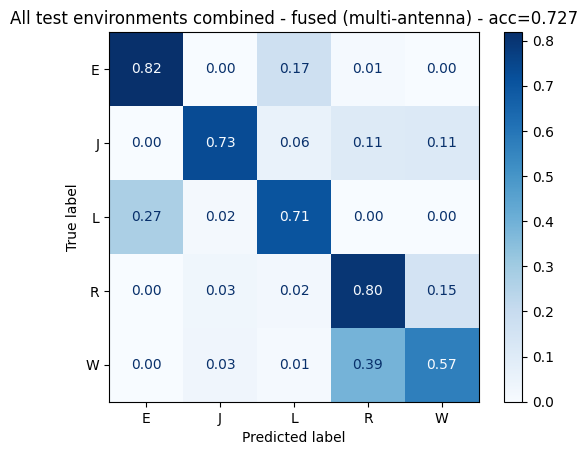

In [ ]:
probs_test, labels_test = get_probabilities(test_dataloader, model)  # test_dataloader has shuffle=False, so this lines up with groups_test
fused_preds, fused_labels = fuse_by_group(probs_test, labels_test, groups_test)
fused_acc = accuracy_score(fused_labels, fused_preds)

print(f"Single-antenna test accuracy (section 6): {test_acc:.4f}  (n={len(y_test)} antenna-level windows)")
print(f"Fused (multi-antenna) test accuracy:       {fused_acc:.4f}  (n={len(fused_labels)} real time windows)")

cm = confusion_matrix(fused_labels, fused_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
disp.plot(cmap="Blues", values_format=".2f")
plt.title(f"All test environments combined - fused (multi-antenna) - acc={fused_acc:.3f}")
plt.show()


## 9. Multi-antenna decision fusion (grouped by measurement set)

Same idea as section 7, but using the fused (multi-antenna) predictions from section 8 instead of single-antenna ones.


S2 (S2a, S2b): fused_acc=0.7709 (n_time_windows=7924, n_antenna_windows=31696)


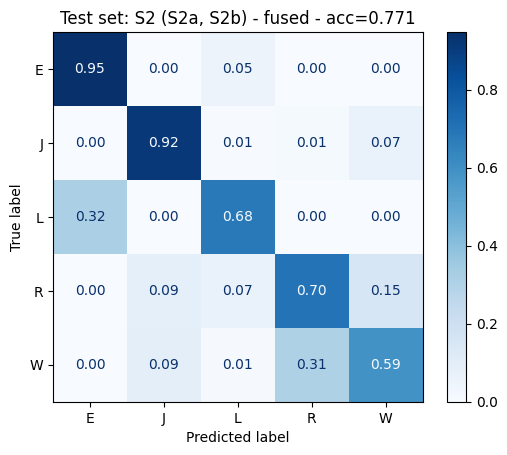

S3 (S3a): fused_acc=0.7735 (n_time_windows=3095, n_antenna_windows=12380)


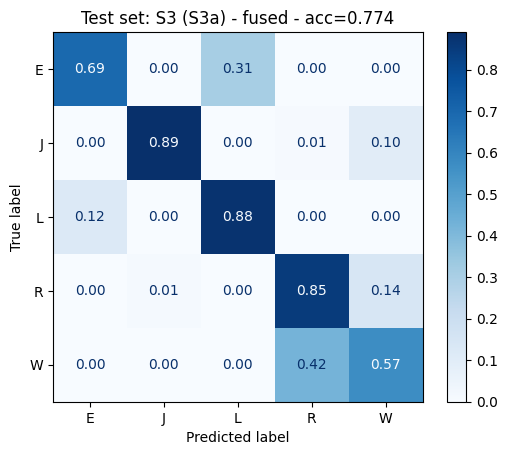

S4 (S4a, S4b): fused_acc=0.6637 (n_time_windows=6111, n_antenna_windows=24444)


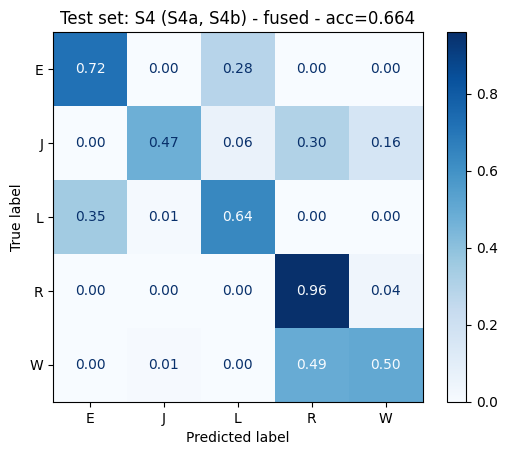

S5 (S5a): fused_acc=0.6643 (n_time_windows=3062, n_antenna_windows=12248)


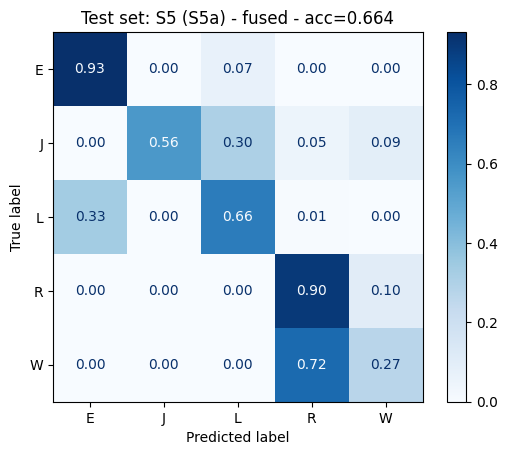

S6 (S6a, S6b): fused_acc=0.7519 (n_time_windows=5868, n_antenna_windows=23472)


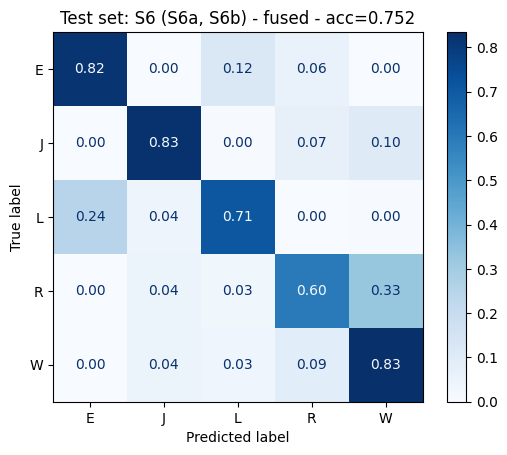

S7 (S7a): fused_acc=0.7065 (n_time_windows=2872, n_antenna_windows=11488)


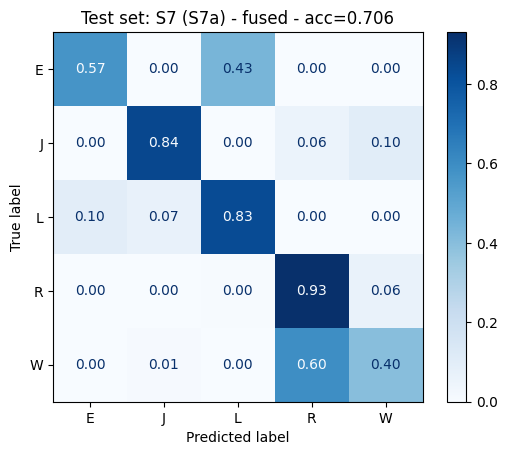

In [ ]:
def evaluate_environment_group_fused(group_name, member_envs):
    mask = np.isin(envs_test, member_envs)       # windows belonging to any environment in this group
    if mask.sum() == 0:
        print(f"{group_name}: no windows found, skipping")
        return None

    X_grp, y_grp, groups_grp = X_test[mask], y_test[mask], groups_test[mask]
    grp_dataset = DopplerDataset(X_grp, y_grp)
    grp_dataloader = DataLoader(grp_dataset, batch_size=BATCH_SIZE, shuffle=False)  # shuffle=False keeps alignment with groups_grp

    probs, labels = get_probabilities(grp_dataloader, model)
    fused_preds, fused_labels = fuse_by_group(probs, labels, groups_grp)
    fused_acc = accuracy_score(fused_labels, fused_preds)
    print(f"{group_name} ({', '.join(member_envs)}): fused_acc={fused_acc:.4f} "
          f"(n_time_windows={len(fused_labels)}, n_antenna_windows={len(y_grp)})")

    cm = confusion_matrix(fused_labels, fused_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
    disp = ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES)
    disp.plot(cmap="Blues", values_format=".2f")
    plt.title(f"Test set: {group_name} ({', '.join(member_envs)}) - fused - acc={fused_acc:.3f}")
    plt.show()
    return fused_acc


per_group_fused_acc = {}
for group_name, member_envs in sorted(test_groups.items()):
    per_group_fused_acc[group_name] = evaluate_environment_group_fused(group_name, member_envs)


## 10. Supervised Contrastive Learning

The baseline suffers from domain shift when trained on S1 and tested on unseen environments. To improve generalization, we use Supervised Contrastive Learning (SupCon) [Khosla et al., NeurIPS 2020].

SupCon trains an encoder to place samples of the same activity close together and different activities farther apart. Augmentations create varied views of each sample. We then freeze the encoder and train a linear classifier. We also evaluate fine-tuning and visualize the embeddings with t-SNE.

In [ ]:
# ---- Setup and hyper-parameters for the contrastive stage -------------------
import copy
import torch.nn.functional as F                 # functional API: used for L2-normalisation of the embeddings
from torch.utils.data import TensorDataset       # lets us wrap the pre-computed feature tensors as a Dataset

# Re-seed here so this section is reproducible on its own, independent of how
# many random numbers the earlier cells happened to draw.
torch.manual_seed(seed)
np.random.seed(seed)

FEATURE_DIM = 128     # size of the representation ("backbone" output) the encoder produces
PROJ_DIM    = 128     # size of the projection-head output; the contrastive loss lives in this space
TEMPERATURE = 0.07    # SupCon temperature: smaller -> sharper contrast. 0.07 is the value used in the paper
CL_EPOCHS   = 30      # upper bound on contrastive pre-training epochs (early stopping usually stops earlier)
CL_PATIENCE = 7       # early-stopping patience on the validation contrastive loss
CL_LR       = 1e-4    # Adam learning rate for the contrastive stage

# Pull the baseline results from sections 6-7 so we can compare against them at the end.
# globals().get(...) keeps this cell runnable even if those exact cells were not re-run in this session.
baseline_test_acc      = globals().get("test_acc", None)
baseline_per_group_acc = dict(globals().get("per_group_acc", {}))
print("Baseline overall test accuracy:", baseline_test_acc)
print("Baseline per-group accuracy   :", baseline_per_group_acc)

Baseline overall test accuracy: 0.6008226185538504
Baseline per-group accuracy   : {'S2': 0.6163238263503281, 'S3': 0.6326332794830372, 'S4': 0.5707331042382588, 'S5': 0.5799314173742652, 'S6': 0.5826942740286298, 'S7': 0.6471100278551533}


### 10.1 Data augmentation

Each window is transformed into two views that preserve the activity while changing unimportant details:

- Amplitude scaling simulates different signal strengths.
- Gaussian noise simulates measurement noise.
- Circular time shifting changes the activity’s starting position.
- Time and Doppler masking hides random regions, encouraging the encode

In [ ]:
def augment(x, noise_std=0.05, max_time_shift=40, time_mask=40, dopp_mask=15, scale_range=(0.8, 1.2)):
    """Return an augmented view of a batch of Doppler windows.

    Args:
        x: float tensor of shape (B, 1, WIN_LEN, N_DOPPLER_BINS) on `device`.
    The activity label is preserved; only nuisance factors are perturbed.
    """
    B, _, T, D = x.shape

    # 1) per-sample amplitude scaling (each window multiplied by its own random gain)
    scale = torch.empty(B, 1, 1, 1, device=x.device).uniform_(*scale_range)
    out = x * scale

    # 2) additive Gaussian noise
    out = out + torch.randn_like(out) * noise_std

    # 3) circular shift along the time axis (dim=2) -> temporal translation invariance
    shift = int(torch.randint(-max_time_shift, max_time_shift + 1, (1,)).item())
    out = torch.roll(out, shifts=shift, dims=2)

    # 4) SpecAugment-style masking: build 0/1 masks and multiply (no in-place ops, autograd-safe).
    #    A random contiguous band along time is zeroed...
    t0 = int(torch.randint(0, max(1, T - time_mask), (1,)).item())
    tmask = torch.ones(1, 1, T, 1, device=x.device)
    tmask[:, :, t0:t0 + time_mask, :] = 0.0
    #    ...and a random contiguous band along the Doppler (velocity) bins.
    d0 = int(torch.randint(0, max(1, D - dopp_mask), (1,)).item())
    dmask = torch.ones(1, 1, 1, D, device=x.device)
    dmask[:, :, :, d0:d0 + dopp_mask] = 0.0

    return out * tmask * dmask

### 10.2 The encoder and the projection head

The encoder is a deeper, batch-normalised evolution of the baseline's block. Three key differences make
it more expressive while staying small:

- **Batch normalisation** after every convolution: stabilises training and helps generalization.
- **A second convolutional stage** that downsamples further, so the network sees a larger receptive field.
- **Global average pooling** instead of the baseline's giant `flatten -> dense`: it produces a fixed-size
  `FEATURE_DIM` vector with far fewer parameters and is naturally more robust to shifts.

The projection head is a small MLP used only during contrastive training. The SupCon paper shows it is better to
apply the contrastive loss on a projected, L2-normalised embedding `z` (on the unit hypersphere) and then throw the
head away, using the encoder output `h` for the actual classification. So we keep two outputs: `h` (for the
classifier) and `z` (for the loss).

In [ ]:
class InceptionBlock(nn.Module):
    """Three parallel branches (pool / strided conv / deeper conv) concatenated on the channel axis.
    All branches halve the spatial size to (WIN_LEN/2, N_DOPPLER_BINS/2) so they can be concatenated."""
    def __init__(self, in_ch=1):
        super().__init__()
        self.branch1 = nn.MaxPool2d(kernel_size=2, stride=2)                      # -> in_ch channels
        self.branch2 = nn.Sequential(                                             # -> 16 channels
            nn.Conv2d(in_ch, 16, kernel_size=3, stride=2, padding=1),
            nn.BatchNorm2d(16), nn.ReLU(),
        )
        self.branch3 = nn.Sequential(                                             # -> 24 channels
            nn.Conv2d(in_ch, 16, kernel_size=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 24, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(24), nn.ReLU(),
        )

    def forward(self, x):
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x)], dim=1)  # in_ch + 16 + 24 channels


class ContrastiveEncoder(nn.Module):
    """Maps a (B, 1, 340, 100) window to a FEATURE_DIM-dimensional representation h."""
    def __init__(self, feature_dim=FEATURE_DIM):
        super().__init__()
        self.feature_dim = feature_dim
        self.inception = InceptionBlock(in_ch=1)                                  # -> (B, 41, 170, 50)
        self.reduce = nn.Sequential(                                              # mix the 41 branch channels -> 32
            nn.Conv2d(1 + 16 + 24, 32, kernel_size=1), nn.BatchNorm2d(32), nn.ReLU(),
        )
        self.stage2 = nn.Sequential(                                              # deeper, downsampling stage
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, feature_dim, kernel_size=3, stride=2, padding=1), nn.BatchNorm2d(feature_dim), nn.ReLU(),
        )
        self.gap = nn.AdaptiveAvgPool2d(1)                                        # -> (B, feature_dim, 1, 1)

    def forward(self, x):
        x = self.inception(x)
        x = self.reduce(x)
        x = self.stage2(x)
        x = self.gap(x).flatten(1)                                                # -> (B, feature_dim)
        return x


class ProjectionHead(nn.Module):
    """Small MLP used only by the contrastive loss; outputs an L2-normalised vector (a point on the unit sphere)."""
    def __init__(self, in_dim=FEATURE_DIM, hidden=PROJ_DIM, out_dim=PROJ_DIM):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, out_dim))

    def forward(self, x):
        return F.normalize(self.net(x), dim=1)   # unit-norm so the dot product below equals the cosine similarity


# instantiate and sanity-check shapes / parameter count
encoder   = ContrastiveEncoder(FEATURE_DIM).to(device)
proj_head = ProjectionHead(FEATURE_DIM, PROJ_DIM, PROJ_DIM).to(device)

with torch.no_grad():
    _dummy = torch.zeros(4, 1, WIN_LEN, N_DOPPLER_BINS).to(device)
    _h = encoder(_dummy)
    _z = proj_head(_h)
    print("encoder output h:", tuple(_h.shape), "| projection z:", tuple(_z.shape),
          "| |z| =", _z.norm(dim=1).mean().item())   # |z| should be ~1.0

n_params = sum(p.numel() for p in encoder.parameters()) + sum(p.numel() for p in proj_head.parameters())
print(f"Contrastive model trainable parameters: {n_params:,}  (baseline was ~128,535)")

encoder output h: (4, 128) | projection z: (4, 128) | |z| = 0.9999999403953552
Contrastive model trainable parameters: 130,952  (baseline was ~128,535)


### 10.3 The Supervised Contrastive (SupCon) loss

For a batch of L2-normalised embeddings, the SupCon loss makes each anchor attract every other sample sharing its label (its positives) and repel everything else, using a softmax over cosine similarities scaled by the temperature:

$$\mathcal{L} = \sum_{i} \frac{-1}{|P(i)|} \sum_{p \in P(i)} \log \frac{\exp(z_i \cdot z_p / \tau)}{\sum_{a \neq i} \exp(z_i \cdot z_a / \tau)}$$

where `P(i)` is the set of samples with the same label as `i` (excluding `i` itself). Unlike SimCLR, this uses the
labels, so all same-activity windows in the batch become positives.
That is what turns generic contrastive learning into an environment-invariant activity representation.

In [ ]:
def supcon_loss(features, labels, temperature=TEMPERATURE):
    """Supervised Contrastive loss (Khosla et al., 2020).

    Args:
        features: (B, d) tensor, assumed already L2-normalised (as produced by ProjectionHead).
        labels:   (B,) integer class labels.
    """
    device_ = features.device
    B = features.shape[0]

    # cosine similarity matrix scaled by temperature; subtract the row-max for numerical stability
    sim = features @ features.t() / temperature
    sim = sim - sim.max(dim=1, keepdim=True)[0].detach()

    labels = labels.contiguous().view(-1, 1)
    same_label = (labels == labels.t()).float().to(device_)     # 1 where two samples share the label
    self_mask  = torch.eye(B, device=device_)                   # 1 on the diagonal (a sample vs itself)
    pos_mask   = same_label * (1.0 - self_mask)                 # positives = same label, excluding self

    # denominator sums over all samples except the anchor itself
    exp_sim  = torch.exp(sim) * (1.0 - self_mask)
    log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-12)

    # average the log-probability over the positives of each anchor
    pos_count = pos_mask.sum(dim=1)
    mean_log_prob_pos = (pos_mask * log_prob).sum(dim=1) / pos_count.clamp(min=1.0)

    # only anchors that actually have at least one positive contribute (always true when we use two views)
    loss = -mean_log_prob_pos
    return loss[pos_count > 0].mean()


# sanity check: perfectly separated clusters should give a very low loss
_f = F.normalize(torch.tensor([[1., 0.], [1., 0.], [0., 1.], [0., 1.]]), dim=1)
_l = torch.tensor([0, 0, 1, 1])
print("SupCon sanity loss (well separated):", round(supcon_loss(_f, _l, 0.07).item(), 4))

SupCon sanity loss (well separated): 0.0


### 10.4 Contrastive pre-training

We now train the encoder + projection head on the training environments only (same `S1`-based split as the baseline, so the comparison is fair). Each batch is turned into two augmented views; the SupCon loss then organises the embedding space. We monitor the loss on the validation split and keep the best encoder weights (early stopping).

  3%|▎         | 1/30 [01:14<36:01, 74.53s/it]

[contrastive] epoch 1/30 - train_loss: 4.5190 - val_loss: 4.4854


  7%|▋         | 2/30 [02:27<34:23, 73.71s/it]

[contrastive] epoch 2/30 - train_loss: 4.4657 - val_loss: 4.4805


 10%|█         | 3/30 [03:40<33:01, 73.37s/it]

...

[contrastive] epoch 28/30 - train_loss: 4.2682 - val_loss: 4.3304


 97%|█████████▋| 29/30 [35:20<01:13, 73.03s/it]

[contrastive] epoch 29/30 - train_loss: 4.2614 - val_loss: 4.3119


100%|██████████| 30/30 [36:34<00:00, 73.14s/it]

[contrastive] epoch 30/30 - train_loss: 4.2628 - val_loss: 4.3071
Restored best encoder (val contrastive loss = 4.2882).


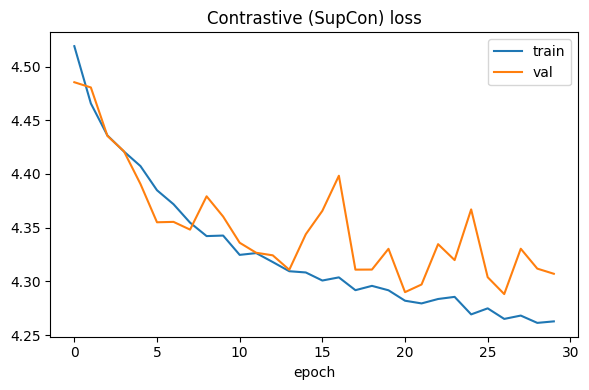

In [ ]:
def run_supcon_epoch(dataloader, encoder, head, optimizer=None):
    """One epoch of contrastive training (optimizer given) or evaluation (optimizer=None)."""
    is_train = optimizer is not None
    encoder.train(); head.train()
    if not is_train:
        encoder.eval(); head.eval()

    total_loss, n = 0.0, 0
    with torch.set_grad_enabled(is_train):
        for batch_x, batch_y in dataloader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # two independent augmented views of the same batch, stacked along the batch axis
            views  = torch.cat([augment(batch_x), augment(batch_x)], dim=0)
            labels = torch.cat([batch_y, batch_y], dim=0)          # both views keep the original label

            z = head(encoder(views))                               # (2B, PROJ_DIM), L2-normalised
            loss = supcon_loss(z, labels, TEMPERATURE)

            if is_train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()

            total_loss += loss.item() * batch_x.size(0); n += batch_x.size(0)
    return total_loss / n


cl_optimizer = torch.optim.Adam(
    list(encoder.parameters()) + list(proj_head.parameters()), lr=CL_LR, weight_decay=1e-4
)

cl_train_losses, cl_val_losses = [], []
best_cl_val = float("inf"); cl_no_improve = 0
best_encoder_state, best_head_state = None, None

for epoch in tqdm(range(CL_EPOCHS)):
    tr = run_supcon_epoch(train_dataloader, encoder, proj_head, cl_optimizer)   # train
    va = run_supcon_epoch(val_dataloader,   encoder, proj_head, optimizer=None)  # validate
    cl_train_losses.append(tr); cl_val_losses.append(va)
    print(f"[contrastive] epoch {epoch+1}/{CL_EPOCHS} - train_loss: {tr:.4f} - val_loss: {va:.4f}")

    if va < best_cl_val:                                    # snapshot the best (lowest val loss) weights
        best_cl_val = va; cl_no_improve = 0
        best_encoder_state = {k: v.detach().cpu().clone() for k, v in encoder.state_dict().items()}
        best_head_state    = {k: v.detach().cpu().clone() for k, v in proj_head.state_dict().items()}
    else:
        cl_no_improve += 1
    if cl_no_improve >= CL_PATIENCE:
        print(f"Early stopping contrastive pre-training at epoch {epoch+1}.")
        break

# restore the best encoder (the projection head has done its job and won't be needed for classification)
if best_encoder_state is not None:
    encoder.load_state_dict(best_encoder_state)
    proj_head.load_state_dict(best_head_state)
    print(f"Restored best encoder (val contrastive loss = {best_cl_val:.4f}).")

plt.figure(figsize=(6, 4))
plt.plot(cl_train_losses, label="train"); plt.plot(cl_val_losses, label="val")
plt.title("Contrastive (SupCon) loss"); plt.xlabel("epoch"); plt.legend(); plt.tight_layout(); plt.show()

### 10.5 Linear evaluation (linear probe)

Standard protocol to measure the quality of a representation: freeze the encoder, pre-compute the embeddings once,
and train only a single `Linear` layer on top with ordinary cross-entropy. If the contrastive representation truly
captured activity structure, this linear classifier should already generalise well to the unseen environments.

In [ ]:
@torch.no_grad()
def extract_features(encoder, dataset, batch_size=256):
    """Run the frozen encoder over a dataset and return (features, labels) tensors, kept in the original order."""
    encoder.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)
    feats, labels = [], []
    for bx, by in loader:
        feats.append(encoder(bx.to(device)).cpu())
        labels.append(by)
    return torch.cat(feats), torch.cat(labels)


# pre-compute embeddings for the three splits
feat_train, ytr = extract_features(encoder, train_dataset)
feat_val,   yva = extract_features(encoder, val_dataset)
feat_test,  yte = extract_features(encoder, test_dataset)

# standardise features using train statistics (helps the linear layer converge)
mu = feat_train.mean(0, keepdim=True); sd = feat_train.std(0, keepdim=True) + 1e-6
ftr, fva, fte = (feat_train - mu) / sd, (feat_val - mu) / sd, (feat_test - mu) / sd

# wrap the feature tensors as datasets and reuse the SAME run_epoch / criterion as the baseline
tr_loader = DataLoader(TensorDataset(ftr, ytr), batch_size=256, shuffle=True)
va_loader = DataLoader(TensorDataset(fva, yva), batch_size=256, shuffle=False)

linear = nn.Linear(FEATURE_DIM, len(ACTIVITIES)).to(device)
probe_optimizer = torch.optim.Adam(linear.parameters(), lr=1e-4, weight_decay=1e-4)

best_probe_val = float("inf"); probe_no_improve = 0; best_probe_state = None
for epoch in range(100):                                   # generous budget; early stopping ends it early
    tr_loss, tr_acc = run_epoch(tr_loader, linear, criterion, probe_optimizer)
    va_loss, va_acc = run_epoch(va_loader, linear, criterion, optimizer=None)
    if va_loss < best_probe_val:
        best_probe_val = va_loss; probe_no_improve = 0
        best_probe_state = {k: v.detach().cpu().clone() for k, v in linear.state_dict().items()}
    else:
        probe_no_improve += 1
    if probe_no_improve >= 10:
        break
linear.load_state_dict(best_probe_state)
print(f"Linear probe trained. Best val loss={best_probe_val:.4f}, val acc={va_acc:.4f} (epoch {epoch+1}).")

Linear probe trained. Best val loss=0.7384, val acc=0.6642 (epoch 100).


### 10.6 Test-set evaluation and comparison with the baseline

We now evaluate the frozen-encoder + linear-probe model on the unseen environments, both overall and grouped by
measurement set (`S2`...`S7`), and put the numbers side-by-side with the baseline from Sections 6-7.

Contrastive overall test accuracy: 0.5953   (baseline: 0.6008)


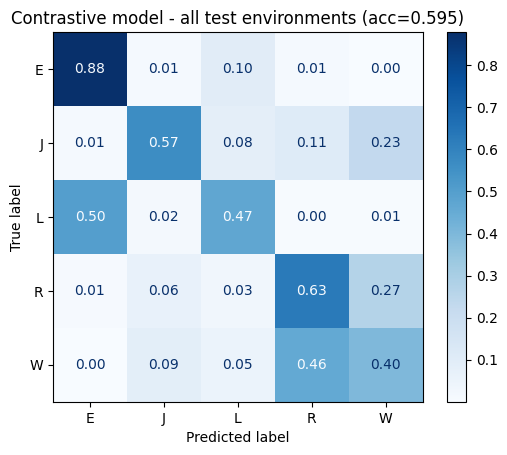

  S2 (S2a, S2b): n=31696, acc=0.6157
  S3 (S3a): n=12380, acc=0.6319
  S4 (S4a, S4b): n=24444, acc=0.5645
  S5 (S5a): n=12248, acc=0.5536
  S6 (S6a, S6b): n=23472, acc=0.5703
  S7 (S7a): n=11488, acc=0.6607


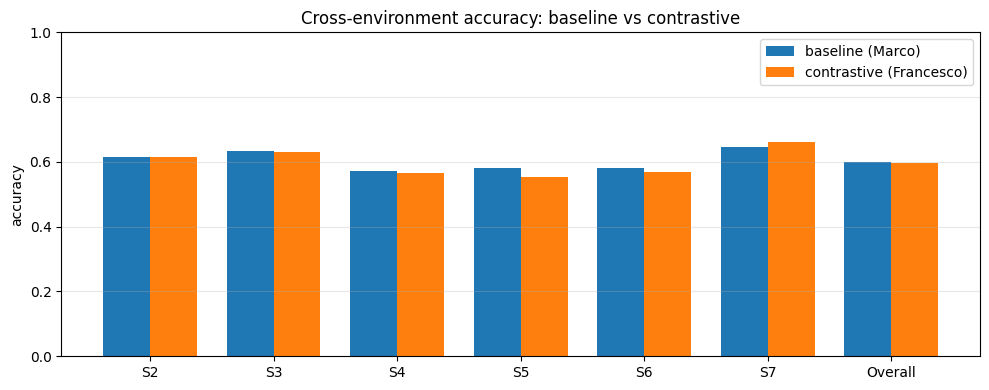

In [ ]:
# overall test predictions and accuracy
linear.eval()
with torch.no_grad():
    cl_test_logits = linear(fte.to(device))
cl_test_preds = cl_test_logits.argmax(1).cpu().numpy()
yte_np = yte.numpy()
cl_test_acc = accuracy_score(yte_np, cl_test_preds)
print(f"Contrastive overall test accuracy: {cl_test_acc:.4f}"
      + (f"   (baseline: {baseline_test_acc:.4f})" if baseline_test_acc is not None else ""))

# overall confusion matrix
cm = confusion_matrix(yte_np, cl_test_preds, labels=list(range(len(ACTIVITIES))), normalize="true")
ConfusionMatrixDisplay(cm, display_labels=ACTIVITIES).plot(cmap="Blues", values_format=".2f")
plt.title(f"Contrastive model - all test environments (acc={cl_test_acc:.3f})"); plt.show()

# per measurement-set group accuracy (reuses test_groups / envs_test built in Section 7)
cl_per_group_acc = {}
for group_name, member_envs in sorted(test_groups.items()):
    mask = np.isin(envs_test, member_envs)
    if mask.sum() == 0:
        continue
    cl_per_group_acc[group_name] = accuracy_score(yte_np[mask], cl_test_preds[mask])
    print(f"  {group_name} ({', '.join(member_envs)}): n={int(mask.sum())}, acc={cl_per_group_acc[group_name]:.4f}")

# side-by-side bar chart: baseline vs contrastive, per group and overall
groups = sorted(cl_per_group_acc.keys())
labels_x = groups + ["Overall"]
base_vals = [baseline_per_group_acc.get(g) if baseline_per_group_acc.get(g) is not None else 0.0 for g in groups]
base_vals += [baseline_test_acc if baseline_test_acc is not None else 0.0]
cl_vals   = [cl_per_group_acc[g] for g in groups] + [cl_test_acc]

x = np.arange(len(labels_x)); w = 0.38
plt.figure(figsize=(10, 4))
plt.bar(x - w/2, base_vals, width=w, label="baseline (Marco)")
plt.bar(x + w/2, cl_vals,  width=w, label="contrastive (Francesco)")
plt.xticks(x, labels_x); plt.ylabel("accuracy"); plt.ylim(0, 1)
plt.title("Cross-environment accuracy: baseline vs contrastive")
plt.legend(); plt.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

### 10.7 End-to-end fine-tuning

The linear probe deliberately keeps the encoder frozen to measure the representation. In practice we can usually
squeeze out a bit more accuracy by unfreezing the encoder and fine-tuning the whole network (encoder + classifier) end-to-end with a small learning rate (small enough not to destroy the contrastive features). We start
from a copy of the pre-trained encoder so the linear-probe results above stay intact.

In [ ]:
class ClassifierModel(nn.Module):
    """Encoder + a linear classification head, trainable end-to-end."""
    def __init__(self, encoder, num_classes):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(encoder.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.encoder(x))


ft_model = ClassifierModel(copy.deepcopy(encoder), len(ACTIVITIES)).to(device)
ft_optimizer = torch.optim.Adam(ft_model.parameters(), lr=1e-4)   # small LR: gently adapt the pre-trained features

best_ft_val = float("inf"); ft_no_improve = 0; best_ft_state = None
for epoch in tqdm(range(20)):
    tr_loss, tr_acc = run_epoch(train_dataloader, ft_model, criterion, ft_optimizer)
    va_loss, va_acc = run_epoch(val_dataloader,   ft_model, criterion, optimizer=None)
    print(f"[fine-tune] epoch {epoch+1} - train_acc: {tr_acc:.4f} - val_acc: {va_acc:.4f}")
    if va_loss < best_ft_val:
        best_ft_val = va_loss; ft_no_improve = 0
        best_ft_state = {k: v.detach().cpu().clone() for k, v in ft_model.state_dict().items()}
    else:
        ft_no_improve += 1
    if ft_no_improve >= 5:
        print(f"Early stopping fine-tuning at epoch {epoch+1}."); break
if best_ft_state is not None:
    ft_model.load_state_dict(best_ft_state)

ft_test_loss, ft_test_acc = run_epoch(test_dataloader, ft_model, criterion, optimizer=None)
print(f"Fine-tuned overall test accuracy: {ft_test_acc:.4f}"
      + (f"   (linear probe: {cl_test_acc:.4f}, baseline: {baseline_test_acc:.4f})"
         if baseline_test_acc is not None else f"   (linear probe: {cl_test_acc:.4f})"))

  5%|▌         | 1/20 [00:36<11:40, 36.85s/it]

[fine-tune] epoch 1 - train_acc: 0.4934 - val_acc: 0.5225


 10%|█         | 2/20 [01:12<10:52, 36.27s/it]

[fine-tune] epoch 2 - train_acc: 0.5709 - val_acc: 0.4881


 15%|█▌        | 3/20 [01:48<10:10, 35.90s/it]

...

 55%|█████▌    | 11/20 [06:36<05:24, 36.07s/it]

[fine-tune] epoch 11 - train_acc: 0.6666 - val_acc: 0.3092


 55%|█████▌    | 11/20 [07:12<05:53, 39.33s/it]

[fine-tune] epoch 12 - train_acc: 0.6742 - val_acc: 0.3607
Early stopping fine-tuning at epoch 12.


Fine-tuned overall test accuracy: 0.5801   (linear probe: 0.5953, baseline: 0.6008)


### 10.8 Visualising the learned representation (t-SNE)

To see whether the encoder learned an environment-invariant activity space, we project a random subset of the test
embeddings to 2-D with t-SNE and colour them two ways:

- **by activity**: if the representation is good, we expect clean, well-separated clusters;
- **by environment group**: if the representation is environment-invariant, the colours here should be mixed
  inside each activity cluster (the encoder is not separating rooms, only activities).

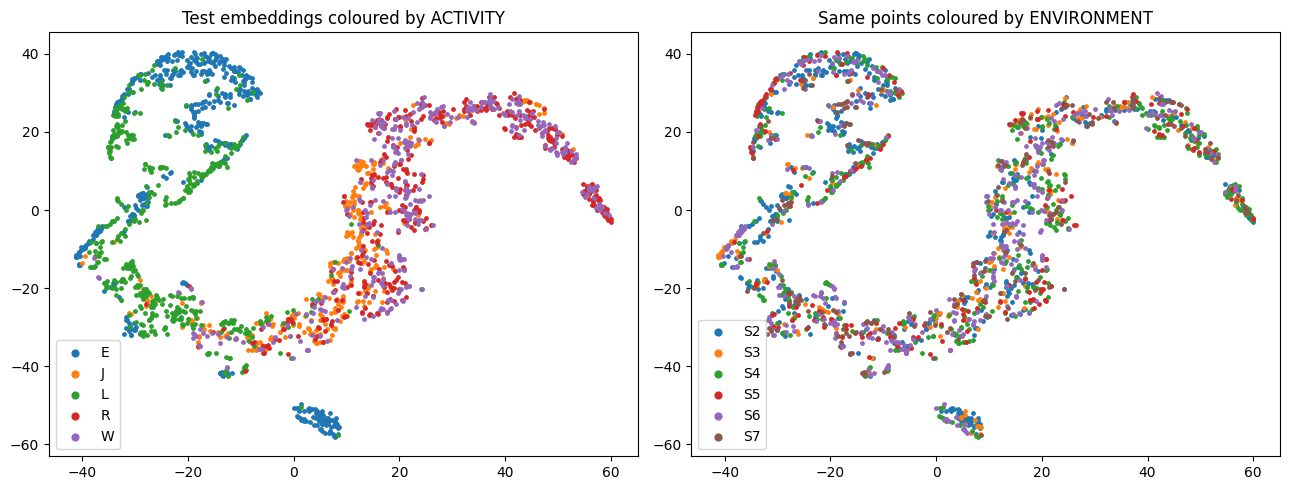

In [ ]:
from sklearn.manifold import TSNE

n_show = min(2000, feat_test.shape[0])                        # t-SNE is slow, so subsample
sel = np.random.choice(feat_test.shape[0], size=n_show, replace=False)
emb2d = TSNE(n_components=2, init="pca", perplexity=30, random_state=seed).fit_transform(feat_test[sel].numpy())

group_of_test = np.array([env_group(e) for e in envs_test])   # measurement-set group per test window
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

# left: colour by activity
for i, act in enumerate(ACTIVITIES):
    m = yte_np[sel] == i
    axs[0].scatter(emb2d[m, 0], emb2d[m, 1], s=6, label=act)
axs[0].set_title("Test embeddings coloured by ACTIVITY"); axs[0].legend(markerscale=2)

# right: colour by environment group
for g in sorted(set(group_of_test[sel])):
    m = group_of_test[sel] == g
    axs[1].scatter(emb2d[m, 0], emb2d[m, 1], s=6, label=g)
axs[1].set_title("Same points coloured by ENVIRONMENT"); axs[1].legend(markerscale=2)
plt.tight_layout(); plt.show()